# Risk Metrics & Out-of-Sample Backtest (Dynamic Top-Down Inputs)

* Edit any input in **Cell 1** (`rf`, `MAX_VOL`, `MIN_MEAN`, `MAX_MEAN`, `MIN_ACTIVE_WT`, `A`, `MONTHLY_USD`, `PROJECT_MONTHS`, `DRAWDOWN_LIMIT`) and run all cells.
* Every accepted stock list, diversification floor, 99% VaR/ES table, out-of-sample growth curve, and monthly accumulation path updates dynamically.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import datetime, json, time, urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.stats import norm
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from matplotlib.ticker import PercentFormatter

COL_NAVY = '#1F4E79'
COL_STEEL = '#5B8DBE'
COL_TEAL = '#1E7166'
COL_CRIMSON = '#B03A2E'
COL_SLATE = '#8C96A0'
COL_AMBER = '#B87333'
COL_PLUM = '#5B4B8A'

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 140, 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold'})
pd.options.display.float_format = '{:,.5f}'.format

# ==============================================================================
# TOP-LEVEL USER INPUTS (Change any value here and run all cells below)
# ==============================================================================
START_DATE = '2021-01-01'
END_DATE = '2025-12-31'
TRAIN_END = '2023-12-31'
N = 252

rf = 0.0434              # Risk-free rate (US 3-Month T-Bill)
rf_base = 0.03           # Archived unscreened 59-stock benchmark risk-free rate
MAX_VOL = 0.32           # Stage 3: maximum annual SD <= MAX_VOL
MIN_MEAN = 0.12          # Stage 4: lower annual return bound E(r) >= MIN_MEAN
MAX_MEAN = 0.25          # Stage 4: upper annual return bound E(r) <= MAX_MEAN
MIN_ACTIVE_WT = 0.01     # Stage 5: minimum active frontier weight (w >= MIN_ACTIVE_WT)

A = 10.0                 # Primary investor risk-aversion coefficient
INTERIM_4 = ['ED', 'NOC', 'GOOGL', 'DE']  # Interim 4-stock test quartet (editable)
A_4 = 6.0                # Interim 4-stock risk-aversion coefficient
MONTHLY_USD = 100.0      # Monthly contribution amount (USD)
PROJECT_MONTHS = 12      # Monthly accumulation horizon (months)
DRAWDOWN_LIMIT = 0.10    # Maximum out-of-sample drawdown threshold
# ==============================================================================

def load_universe():
    for base_dir in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
        fp = base_dir / 'stock_universe.csv'
        if fp.exists():
            df = pd.read_csv(fp)
            df = df[df['Included'].astype(str).str.lower() == 'true'].copy()
            return df['Ticker'].tolist(), dict(zip(df['Ticker'], df['Business']))
    raise FileNotFoundError('Could not find stock_universe.csv')

def fetch_price_series(ticker, start=START_DATE, end=END_DATE):
    for base_dir in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
        fp = base_dir / 'data' / f'{ticker}_{start}_{end}.csv'
        if fp.exists():
            df = pd.read_csv(fp, parse_dates=['Date']).sort_values('Date')
            col = 'Adj Close' if 'Adj Close' in df.columns else 'Close'
            return pd.Series(pd.to_numeric(df[col]).to_numpy(), index=df['Date'], name=ticker).loc[start:end]
    p1 = int(pd.Timestamp(start, tz='UTC').timestamp())
    p2 = int((pd.Timestamp(end, tz='UTC') + pd.Timedelta(days=1)).timestamp())
    url = f'https://query1.finance.yahoo.com/v8/finance/chart/{ticker}?period1={p1}&period2={p2}&interval=1d'
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=15) as resp:
        res = json.loads(resp.read().decode())['chart']['result'][0]
    dates = [datetime.datetime.fromtimestamp(x, tz=datetime.timezone.utc).strftime('%Y-%m-%d') for x in res['timestamp']]
    s = pd.Series(pd.to_numeric(res['indicators']['adjclose'][0]['adjclose'], errors='coerce'),
                  index=pd.to_datetime(dates), name=ticker).dropna()
    return s[~s.index.duplicated()].sort_index().loc[start:end]

def load_prices(ticker_list, start=START_DATE, end=END_DATE):
    with ThreadPoolExecutor(max_workers=8) as ex:
        return pd.concat(list(ex.map(lambda t: fetch_price_series(t, start, end), ticker_list)), axis=1).dropna()

def opt_gp(cols, rfr=rf):
    tr = all_train[cols]
    mv = (tr.mean() * N).to_numpy(); cm = (tr.cov() * N).to_numpy()
    m = len(cols); w0 = np.ones(m) / m; b = [(0, 1)] * m; eq = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]
    wg = minimize(lambda w: w @ cm @ w, w0, method='SLSQP', bounds=b, constraints=eq, options={'ftol': 1e-12, 'maxiter': 2000}).x
    wp = minimize(lambda w: -(w @ mv - rfr) / np.sqrt(w @ cm @ w), w0, method='SLSQP', bounds=b, constraints=eq, options={'ftol': 1e-12, 'maxiter': 2000}).x
    return mv, cm, wg, wp

US_UNIVERSE, SECTORS = load_universe()
all_prices = load_prices(US_UNIVERSE, START_DATE, END_DATE)
all_rets = all_prices.pct_change().dropna()
all_train = all_rets.loc[:TRAIN_END]
all_test = all_rets.loc[all_rets.index > pd.Timestamp(TRAIN_END)]
n_raw = len(US_UNIVERSE)

ann_m = all_train.mean() * N
ann_s = all_train.std(ddof=1) * np.sqrt(N)
m_screen = (ann_m > rf) & (ann_s <= MAX_VOL) & (ann_m >= MIN_MEAN) & (ann_m <= MAX_MEAN)
SCREENED = [t for t in US_UNIVERSE if m_screen[t]]
if len(SCREENED) < 2:
    raise ValueError(f'Only {len(SCREENED)} stock(s) passed your screening rules. Relax thresholds in Cell 1.')

_, _, _, w_sc_p = opt_gp(SCREENED, rf)
active_pairs = sorted([(t, float(w)) for t, w in zip(SCREENED, w_sc_p) if w >= MIN_ACTIVE_WT], key=lambda x: -x[1])
if len(active_pairs) < 2:
    active_pairs = sorted([(t, float(w)) for t, w in zip(SCREENED, w_sc_p)], key=lambda x: -x[1])[:2]

SELECTED = [t for t, _ in active_pairs]
k = len(SELECTED)

mu_u, cov_u, wG_u, wP_u = opt_gp(US_UNIVERSE, rf_base)
mu_s, cov_s, wG_s, wP_s = opt_gp(SELECTED, rf)
p_m, p_v, p_s = float(wP_s @ mu_s), float(wP_s @ cov_s @ wP_s), float(np.sqrt(wP_s @ cov_s @ wP_s))
y_star = float(np.clip((p_m - rf) / (A * p_v), 0.0, 1.0))
c_s = y_star * p_s

mu4, cov4, wG4, wP4 = opt_gp(INTERIM_4, rf)
p4_m, p4_v, p4_s = float(wP4 @ mu4), float(wP4 @ cov4 @ wP4), float(np.sqrt(wP4 @ cov4 @ wP4))
y4 = float(np.clip((p4_m - rf) / (A_4 * p4_v), 0.0, 1.0))
c4_s = y4 * p4_s
train_sel, test_sel = all_train[SELECTED], all_test[SELECTED]
train4, test4 = all_train[INTERIM_4], all_test[INTERIM_4]
print(f'Train: {len(all_train)} days | OOS: {len(all_test)} days | Accepted {k} stocks: {SELECTED} | y*={y_star:.2%}')

Train: 752 days | OOS: 502 days | Accepted 8 stocks: ['ABBV', 'NOC', 'COST', 'WM', 'MSFT', 'IBM', 'CAT', 'ORCL'] | y*=83.36%


## Diversification Limit, Risk Pooling, and Time Horizon

Computes the equal-weight diversification decay toward `sqrt(avg_cov)`, fixed vs. pooled capital risk, and `1 to 25 year` horizon scaling.

In [2]:
# 1. Calculate diversification floor, pooling table, and horizon scaling
avg_var = float(np.diag(cov_s).mean())  # Average individual stock variance (diagonal of covariance matrix)
avg_cov = float(cov_s[~np.eye(k, dtype=bool)].mean())  # Average off-diagonal covariance across all stock pairs
ew_var = float((np.ones(k) / k) @ cov_s @ (np.ones(k) / k))  # Equal-weight portfolio variance
floor_sd = np.sqrt(max(avg_cov, 0.0))

n_range = np.arange(1, 51)
ew_curve = np.sqrt(np.maximum(avg_var / n_range + (n_range - 1) / n_range * avg_cov, 0.0))

pool_ns = sorted(set([n_a for n_a in [1, 2, 4, k] if n_a <= k]))
pooling_df = pd.DataFrame([
    {'Assets': n_a,
     f'Fixed ${MONTHLY_USD:g} SD ($)': MONTHLY_USD * float(np.sqrt((np.ones(n_a) / n_a) @ cov_s[:n_a, :n_a] @ (np.ones(n_a) / n_a))),
     'Pooled Total ($)': MONTHLY_USD * n_a,
     'Pooled Total SD ($)': MONTHLY_USD * n_a * float(np.sqrt((np.ones(n_a) / n_a) @ cov_s[:n_a, :n_a] @ (np.ones(n_a) / n_a)))}
    for n_a in pool_ns
])

T_vals = [1, 3, 5, 10, 15, 25]
time_df = pd.DataFrame({
    'Horizon T (years)': T_vals,
    f'{k}-Stock C Avg Annual SD': [c_s / np.sqrt(t) for t in T_vals],
    f'{k}-Stock C Cumulative SD': [c_s * np.sqrt(t) for t in T_vals],
})

In [3]:
# 2. Output diversification floor, pooling, and time-horizon tables
div_summary = pd.DataFrame([
    {'Portfolio': f'{k}-Stock Accepted Frontier', 'Avg Indiv Var': avg_var, 'Avg Cov': avg_cov, 'EW SD': np.sqrt(ew_var), 'Systematic Floor': floor_sd},
])
display(div_summary); display(pooling_df); display(time_df)  # Display formatted summary table

,Portfolio,Avg Indiv Var,Avg Cov,EW SD,Systematic Floor
0,8-Stock Accepted Frontier,0.06176,0.01562,0.14623,0.12497


,Assets,Fixed $100 SD ($),Pooled Total ($),Pooled Total SD ($)
0,1,20.71128,100.00000,20.71128
1,2,17.45644,200.00000,34.91287
2,4,14.78948,400.00000,59.15792
3,8,14.62322,800.00000,116.98575


,Horizon T (years),8-Stock C Avg Annual SD,8-Stock C Cumulative SD
0,1,0.11627,0.11627
1,3,0.06713,0.20139
2,5,0.05200,0.25999
3,10,0.03677,0.36768
4,15,0.03002,0.45031
5,25,0.02325,0.58135


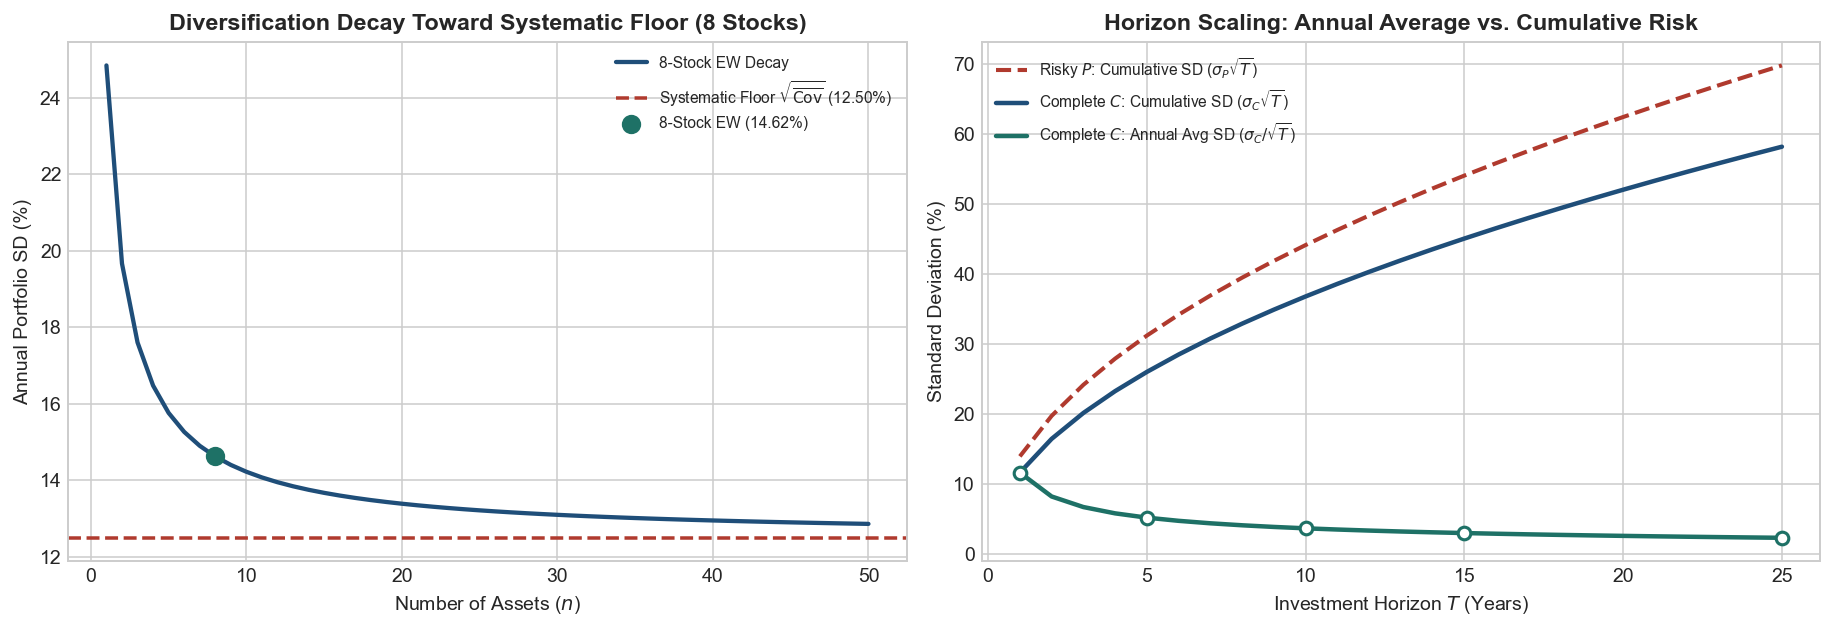

In [4]:
# 3. Draw diversification limit curve and horizon scaling chart (Paper Fig. 8 style)
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.6))
fig.patch.set_facecolor('#FFFFFF')
axes[0].plot(n_range, ew_curve * 100, color=COL_NAVY, lw=2.2, label=f'{k}-Stock EW Decay')
axes[0].axhline(floor_sd * 100, color=COL_CRIMSON, linestyle='--', lw=1.8, label=rf'Systematic Floor $\sqrt{{\overline{{\mathrm{{Cov}}}}}}$ ({floor_sd:.2%})')
axes[0].scatter([k], [np.sqrt(ew_var) * 100], color=COL_TEAL, s=80, zorder=5, label=f'{k}-Stock EW ({np.sqrt(ew_var):.2%})')
axes[0].set(xlabel=r'Number of Assets ($n$)', ylabel='Annual Portfolio SD (%)', title=f'Diversification Decay Toward Systematic Floor ({k} Stocks)')
axes[0].legend(fontsize=8)

tc = np.arange(1, 26)
axes[1].plot(tc, p_s * np.sqrt(tc) * 100, color=COL_CRIMSON, linestyle='--', lw=2.1, label=r'Risky $P$: Cumulative SD ($\sigma_P\sqrt{T}$)')
axes[1].plot(tc, c_s * np.sqrt(tc) * 100, color=COL_NAVY, lw=2.3, label=r'Complete $C$: Cumulative SD ($\sigma_C\sqrt{T}$)')
axes[1].plot(tc, (c_s / np.sqrt(tc)) * 100, color=COL_TEAL, lw=2.3, label=r'Complete $C$: Annual Avg SD ($\sigma_C/\sqrt{T}$)')
mark_t = np.array([1, 5, 10, 15, 25])
axes[1].scatter(mark_t, (c_s / np.sqrt(mark_t)) * 100, facecolor='#FFFFFF', edgecolor=COL_TEAL, s=42, lw=1.6, zorder=5)
axes[1].set(xlabel=r'Investment Horizon $T$ (Years)', ylabel='Standard Deviation (%)', title='Horizon Scaling: Annual Average vs. Cumulative Risk')
axes[1].legend(fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()

## Value at Risk (99% VaR) & Expected Shortfall (ES)

Compares Normal-distribution tail estimates against empirical 1-day worst-1% losses and 10,000 bootstrap draws.

In [5]:
# 1. Calculate 99% VaR, Expected Shortfall, and bootstrap intervals
z99 = norm.ppf(0.99); es_mult = norm.pdf(z99) / 0.01
est_lbl = f'{START_DATE[:4]}-{TRAIN_END[:4]} Est'
oos_lbl = f'{test_sel.index.min().year}-{END_DATE[:4]} OOS'

tail_rows = []
for plbl, d_sel, d_u in [(est_lbl, train_sel, all_train), (oos_lbl, test_sel, all_test)]:
    series_list = [
        (f'{k}-Stock G', d_sel.to_numpy() @ wG_s),
        (f'{k}-Stock P', d_sel.to_numpy() @ wP_s),
        (f'{k}-Stock C (A={A:g})', y_star * (d_sel.to_numpy() @ wP_s) + (1.0 - y_star) * (rf / N)),
        (f'{n_raw}-Stock Unscreened P', d_u.to_numpy() @ wP_u),
    ]
    for label, r in series_list:
        d_mu, d_sd = float(r.mean()), float(r.std(ddof=1))
        losses = -r; h_var = float(np.quantile(losses, 0.99)); h_es = float(losses[losses >= h_var].mean())
        rng = np.random.default_rng(7)
        b_es = [float((samp := rng.choice(losses, size=len(losses), replace=True))[samp >= np.quantile(samp, 0.99)].mean()) for _ in range(10000)]
        w_curve = np.r_[1.0, np.cumprod(1.0 + r)]; mdd = float((w_curve / np.maximum.accumulate(w_curve) - 1.0).min())
        tail_rows.append({'Period': plbl, 'Portfolio': label, 'Daily SD': d_sd, 'Annual SD': d_sd * np.sqrt(N), 'Max Drawdown': mdd,
                          'Normal 99% VaR': -(d_mu - z99 * d_sd), 'Historical 99% VaR': h_var,
                          'Normal 99% ES': -(d_mu - es_mult * d_sd), 'Historical 99% ES': h_es,
                          'Bootstrap ES 5th': float(np.quantile(b_es, 0.05)), 'Bootstrap ES 95th': float(np.quantile(b_es, 0.95))})
tail_df = pd.DataFrame(tail_rows)

In [6]:
# 2. Output VaR and Expected Shortfall comparison table
display(tail_df)  # Display formatted summary table

,Period,Portfolio,Daily SD,Annual SD,Max Drawdown,Normal 99% VaR,Historical 99% VaR,Normal 99% ES,Historical 99% ES,Bootstrap ES 5th,Bootstrap ES 95th
0,2021-2023 Est,8-Stock G,0.00853,0.13533,-0.11200,0.01905,0.02267,0.02194,0.02655,0.02294,0.02985
1,2021-2023 Est,8-Stock P,0.00879,0.13947,-0.13884,0.01962,0.02224,0.02260,0.02854,0.02337,0.03305
2,2021-2023 Est,8-Stock C (A=10),0.00732,0.11627,-0.11381,0.01633,0.01851,0.01881,0.02376,0.01946,0.02752
3,2021-2023 Est,59-Stock Unscreened P,0.01148,0.18231,-0.15759,0.02528,0.02696,0.02918,0.03496,0.02929,0.03905
4,2024-2025 OOS,8-Stock G,0.00825,0.13097,-0.10930,0.01827,0.02001,0.02107,0.02978,0.01980,0.04128
5,2024-2025 OOS,8-Stock P,0.00815,0.12940,-0.11382,0.01803,0.01938,0.02079,0.02947,0.02000,0.04077
6,2024-2025 OOS,8-Stock C (A=10),0.00680,0.10787,-0.09485,0.01500,0.01613,0.01730,0.02454,0.01664,0.03396
7,2024-2025 OOS,59-Stock Unscreened P,0.01074,0.17049,-0.15882,0.02391,0.02371,0.02755,0.04057,0.02583,0.05310


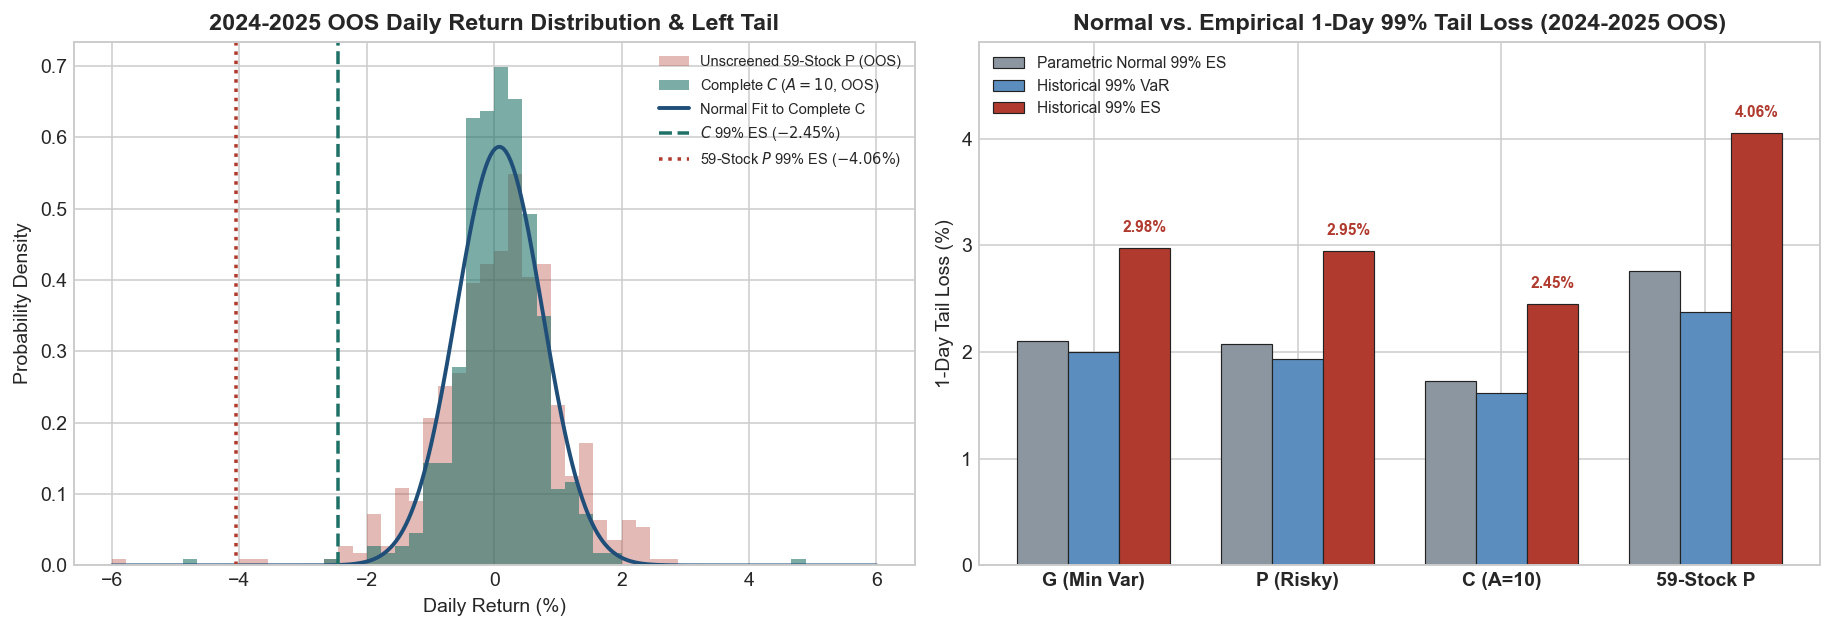

In [7]:
# 3. Draw OOS return histogram and 99% tail loss comparison bars (Paper Fig. 7 style)
rC_oos_arr = y_star * (test_sel.to_numpy() @ wP_s) + (1.0 - y_star) * (rf / N)
rU_oos_arr = all_test.to_numpy() @ wP_u
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.6))
fig.patch.set_facecolor('#FFFFFF')
bins = np.linspace(-0.06, 0.06, 55)
axes[0].hist(rU_oos_arr * 100, bins=bins * 100, density=True, alpha=0.35, color=COL_CRIMSON, label=f'Unscreened {n_raw}-Stock P (OOS)')
axes[0].hist(rC_oos_arr * 100, bins=bins * 100, density=True, alpha=0.58, color=COL_TEAL, label=rf'Complete $C$ ($A={A:g}$, OOS)')
xg = np.linspace(-6, 6, 300)
axes[0].plot(xg, norm.pdf(xg, rC_oos_arr.mean() * 100, rC_oos_arr.std(ddof=1) * 100), color=COL_NAVY, lw=2.0, label='Normal Fit to Complete C')
c_es_val = float(tail_df[(tail_df['Period'] == oos_lbl) & (tail_df['Portfolio'] == f'{k}-Stock C (A={A:g})')]['Historical 99% ES'].iloc[0]) * 100
u_es_val = float(tail_df[(tail_df['Period'] == oos_lbl) & (tail_df['Portfolio'] == f'{n_raw}-Stock Unscreened P')]['Historical 99% ES'].iloc[0]) * 100
axes[0].axvline(-c_es_val, color=COL_TEAL, linestyle='--', lw=1.8, label=rf'$C$ 99% ES ($-{c_es_val:.2f}\%$)')
axes[0].axvline(-u_es_val, color=COL_CRIMSON, linestyle=':', lw=1.8, label=rf'{n_raw}-Stock $P$ 99% ES ($-{u_es_val:.2f}\%$)')
axes[0].set(xlabel='Daily Return (%)', ylabel='Probability Density', title=f'{oos_lbl} Daily Return Distribution & Left Tail')
axes[0].legend(fontsize=7.5, loc='upper right')

oos_sub = tail_df[tail_df['Period'] == oos_lbl]
xt = np.arange(len(oos_sub)); bw = 0.25
axes[1].bar(xt - bw, oos_sub['Normal 99% ES'] * 100, width=bw, color=COL_SLATE, edgecolor='#222222', linewidth=0.6, label='Parametric Normal 99% ES')
axes[1].bar(xt, oos_sub['Historical 99% VaR'] * 100, width=bw, color=COL_STEEL, edgecolor='#222222', linewidth=0.6, label='Historical 99% VaR')
axes[1].bar(xt + bw, oos_sub['Historical 99% ES'] * 100, width=bw, color=COL_CRIMSON, edgecolor='#222222', linewidth=0.6, label='Historical 99% ES')
for idx_bar, val in enumerate(oos_sub['Historical 99% ES'] * 100):
    axes[1].text(idx_bar + bw, val + 0.12, f'{val:.2f}%', ha='center', va='bottom', fontsize=8, fontweight='bold', color=COL_CRIMSON)
axes[1].set_xticks(xt, ['G (Min Var)', 'P (Risky)', f'C (A={A:g})', f'{n_raw}-Stock P'], fontweight='bold')
axes[1].set(ylim=(0, max(4.9, float(oos_sub['Historical 99% ES'].max() * 100) + 0.85)), ylabel='1-Day Tail Loss (%)', title=f'Normal vs. Empirical 1-Day 99% Tail Loss ({oos_lbl})')
axes[1].legend(fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()

## Out-of-Sample Backtest & Monthly Funding Plan

Evaluates frozen training weights on unseen out-of-sample days plus systematic monthly deposits (`MONTHLY_USD` for `PROJECT_MONTHS`).

In [8]:
# 1. Calculate OOS return paths, CAGR, drawdowns, and monthly contributions
rG_oos = pd.Series(test_sel.to_numpy() @ wG_s, index=test_sel.index)  # Daily out-of-sample returns for Min Variance G
rP_oos = pd.Series(test_sel.to_numpy() @ wP_s, index=test_sel.index)  # Daily out-of-sample returns for Max Sharpe P
rC_oos = y_star * rP_oos + (1.0 - y_star) * (rf / N)  # Daily out-of-sample returns for Complete Portfolio C (P + T-bills)
rEW_oos = pd.Series(test_sel.to_numpy() @ (np.ones(k) / k), index=test_sel.index)  # Daily out-of-sample returns for Equal-Weight benchmark
rC4_oos = y4 * pd.Series(test4.to_numpy() @ wP4, index=test4.index) + (1.0 - y4) * (rf / N)
rU_oos = pd.Series(all_test.to_numpy() @ wP_u, index=all_test.index)  # Daily out-of-sample returns for unscreened baseline P

oos_rows = []
for name, s in [
    (f'{k}-Stock G (Min Var)', rG_oos),
    (f'{k}-Stock P (Max Sharpe)', rP_oos),
    (f'{k}-Stock C (y*={y_star:.2%}, A={A:g})', rC_oos),
    (f'{k}-Stock Equal-Weight', rEW_oos),
    (f'{len(INTERIM_4)}-Stock Interim C (y*={y4:.2%}, A={A_4:g})', rC4_oos),
    (f'{n_raw}-Stock Unscreened P', rU_oos),
]:
    mu_a = float(s.mean() * N); cagr = float(np.prod(1.0 + s) ** (N / len(s)) - 1.0)
    sd_a = float(s.std(ddof=1) * np.sqrt(N))
    w_c = np.r_[1.0, np.cumprod(1.0 + s.to_numpy())]
    mdd = float((w_c / np.maximum.accumulate(w_c) - 1.0).min())
    oos_rows.append({'Portfolio': name, 'Annual Mean': mu_a, 'CAGR': cagr, 'Annual SD': sd_a, f'Sharpe (rf={rf:.2%})': (mu_a - rf) / sd_a, 'Max Drawdown': mdd})
oos_comp = pd.DataFrame(oos_rows)

def contribution_path(r_series):
    months = r_series.index.to_period('M').unique()[:PROJECT_MONTHS]
    r_sub = r_series[r_series.index.to_period('M').isin(months)]
    val, paid, prev, recs = 0.0, 0.0, None, []
    for dt, ret in r_sub.items():
        if (dt.year, dt.month) != prev:
            val += MONTHLY_USD; paid += MONTHLY_USD
        val *= (1.0 + float(ret)); recs.append((dt, val, paid, val - paid)); prev = (dt.year, dt.month)
    return pd.DataFrame(recs, columns=['Date', 'Value', 'Contributed', 'Gain']).set_index('Date')

paths_map = {f'{k}-Stock P': rP_oos, f'{k}-Stock C (A={A:g})': rC_oos, f'{k}-Stock EW': rEW_oos, f'{len(INTERIM_4)}-Stock Interim C (A={A_4:g})': rC4_oos, f'{n_raw}-Stock Unscreened P': rU_oos}
funded = {lbl: contribution_path(s) for lbl, s in paths_map.items()}
contrib_summary = pd.DataFrame({lbl: df.iloc[-1] for lbl, df in funded.items()}).T

In [9]:
# 2. Output OOS performance table and monthly funding table
display(oos_comp); display(contrib_summary)  # Display formatted summary table

,Portfolio,Annual Mean,CAGR,Annual SD,Sharpe (rf=4.34%),Max Drawdown
0,8-Stock G (Min Var),0.23244,0.25077,0.13097,1.44330,-0.10930
1,8-Stock P (Max Sharpe),0.23562,0.25502,0.12940,1.48547,-0.11382
2,"8-Stock C (y*=83.36%, A=10)",0.20364,0.21866,0.10787,1.48547,-0.09485
3,8-Stock Equal-Weight,0.25571,0.27833,0.14207,1.49445,-0.13118
4,"4-Stock Interim C (y*=90.44%, A=6)",0.18594,0.19612,0.11677,1.22066,-0.06099
5,59-Stock Unscreened P,0.27090,0.29212,0.17049,1.33436,-0.15882


,Value,Contributed,Gain
8-Stock P,"1,287.93106","1,200.00000",87.93106
8-Stock C (A=10),"1,278.11974","1,200.00000",78.11974
8-Stock EW,"1,313.46580","1,200.00000",113.46580
4-Stock Interim C (A=6),"1,254.65030","1,200.00000",54.65030
59-Stock Unscreened P,"1,266.24527","1,200.00000",66.24527


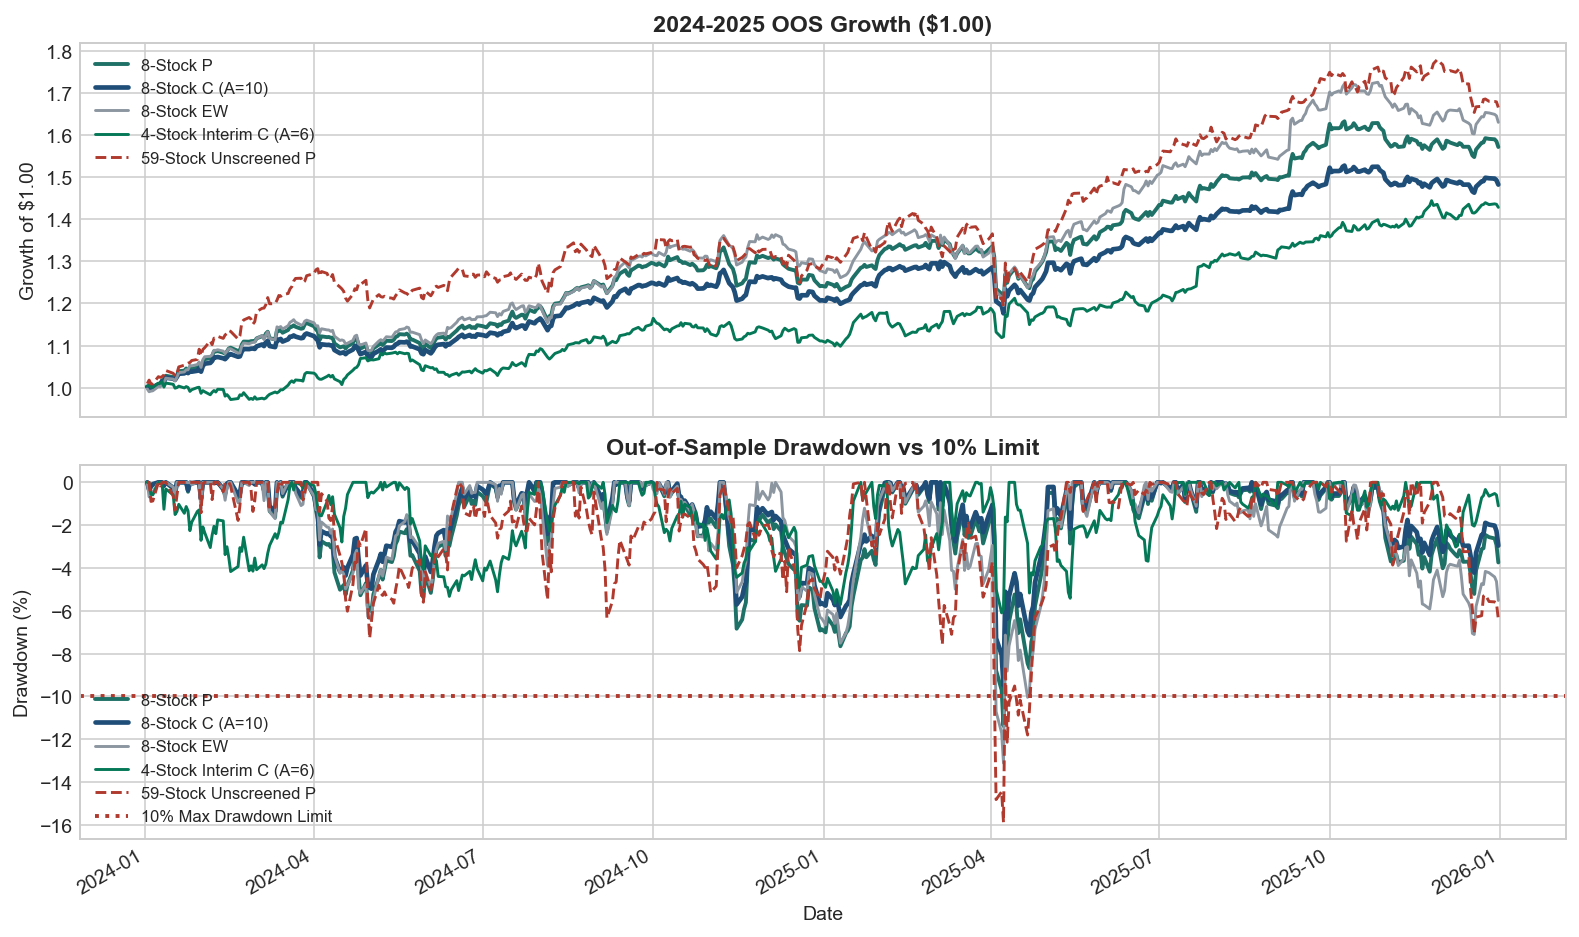

In [10]:
# 3. Draw OOS growth and drawdown vs DRAWDOWN_LIMIT (Paper Fig. 9 style)
fig, axes = plt.subplots(2, 1, figsize=(11.5, 6.8), sharex=True)
fig.patch.set_facecolor('#FFFFFF')
palette = [COL_TEAL, COL_NAVY, COL_SLATE, '#047857', COL_CRIMSON]
for (lbl, s), col in zip(paths_map.items(), palette):
    lw = 2.4 if f'{k}-Stock C' in lbl else (2.0 if f'{k}-Stock P' in lbl else 1.5)
    ls = '--' if 'Unscreened' in lbl else '-'
    w_s = (1.0 + s).cumprod()
    w_s.plot(ax=axes[0], label=lbl, color=col, lw=lw, linestyle=ls)
    ((w_s / w_s.cummax() - 1.0) * 100).plot(ax=axes[1], label=lbl, color=col, lw=lw, linestyle=ls)
axes[0].set(ylabel='Growth of $1.00', title=f'{oos_lbl} Growth ($1.00)')
axes[0].legend(fontsize=8.5, loc='upper left')
axes[1].axhline(-DRAWDOWN_LIMIT * 100, color=COL_CRIMSON, linestyle=':', lw=2.0, label=f'{DRAWDOWN_LIMIT:.0%} Max Drawdown Limit')
axes[1].set(ylabel='Drawdown (%)', title=f'Out-of-Sample Drawdown vs {DRAWDOWN_LIMIT:.0%} Limit')
axes[1].legend(fontsize=8.5, loc='lower left')
plt.tight_layout(); plt.show()

## Dynamic Verification Checks

Verifies weight constraints, PSD covariance, equal-weight variance identity, funding totals, and drawdown compliance.

In [11]:
for w_chk, c_chk in [(wG_s, cov_s), (wP_s, cov_s)]:
    assert abs(w_chk.sum() - 1.0) < 1e-6 and w_chk.min() >= -1e-7  # Verify mathematical and constraint identity
    assert np.allclose(c_chk, c_chk.T) and np.linalg.eigvalsh(c_chk).min() > -1e-10  # Verify mathematical and constraint identity
assert np.isclose(ew_var, avg_var / k + (k - 1) / k * avg_cov, atol=1e-12)  # Verify mathematical and constraint identity
dd_c_oos = tail_df[(tail_df['Period'] == oos_lbl) & (tail_df['Portfolio'] == f'{k}-Stock C (A={A:g})')]['Max Drawdown'].iloc[0]
assert np.isclose(contrib_summary.loc[f'{k}-Stock C (A={A:g})', 'Contributed'], MONTHLY_USD * PROJECT_MONTHS)  # Verify mathematical and constraint identity
dd_status = 'PASS' if abs(dd_c_oos) < DRAWDOWN_LIMIT else f'BREACH (>{DRAWDOWN_LIMIT:.0%})'
print(f'ALL MATH CHECKS PASSED | Accepted {k} stocks: {SELECTED} | OOS C MaxDD={dd_c_oos:.2%} [{dd_status}]')

ALL MATH CHECKS PASSED | Accepted 8 stocks: ['ABBV', 'NOC', 'COST', 'WM', 'MSFT', 'IBM', 'CAT', 'ORCL'] | OOS C MaxDD=-9.48% [PASS]
